# **Proyecto Final:** SwingVision ⛳📷

## **Librerías**

In [1]:
import cv2
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

import config
from utils import show_images, write_image
from calibration import load_calibration, prepare_frame, get_scale
from swing import (build_background, segment_player, get_silhouette_pose, MarkerTracker, find_club_line,
                   analyse_video, detect_positions, compute_measures, get_position_images, get_tracking_quality)
from comparison import (register_reference, load_reference, evaluate, compare, summarise, print_report,
                        draw_ghost, make_strobe, plot_speed, save_results, MEASURE_INFO)

results_path = os.path.join(config.RESULTS_PATH, "partC_swing")
os.makedirs(results_path, exist_ok=True)

calib = load_calibration()

## **Apartado C: Sistema propuesto**

El sistema analiza un swing y lo compara con un swing de referencia. Este cuaderno recorre todos los bloques, uno a uno, con un vídeo grabado; ``main.py`` hace lo mismo en directo.

1. **Tarea C.1.** Fondo de la escena.
2. **Tarea C.2.** Segmentación del jugador (sustracción de fondo + morfología).
3. **Tarea C.3.** Detección de los marcadores por color.
4. **Tarea C.4.** Ángulo del palo con Canny + Hough.
5. **Tarea C.5.** Tracker sobre todo el vídeo.
6. **Tarea C.6.** Detección de las posiciones P.
7. **Tarea C.7.** Medidas del swing.
8. **Tarea C.8.** Referencia.
9. **Tarea C.9.** Comparación con la referencia.
10. **Tarea C.10.** Salida: fantasma, estroboscópica y curva de velocidad.

### **Tarea C.1:** Fondo de la escena

Cada vídeo empieza con unos instantes de la **escena vacía**. El fondo es la mediana de varios de esos frames (la mediana elimina el ruido). Todos los frames pasan antes por ``prepare_frame()``, que corrige la distorsión y los lleva al tamaño de trabajo.

Frames used for the background: 120 - shape: (540, 960, 3)


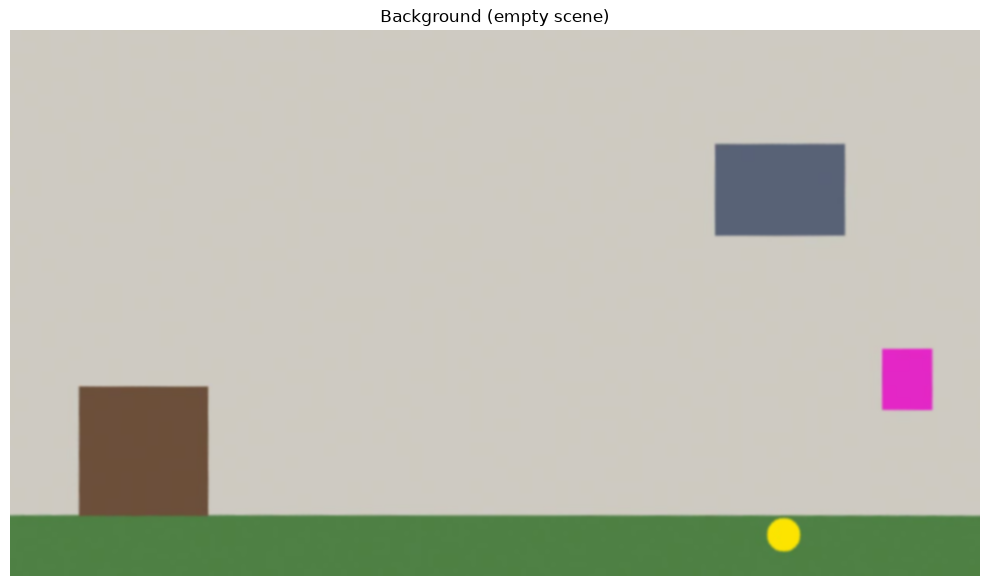

In [2]:
videopath = os.path.join(config.DATA_PATH, "videos", "player", "swing_01.mp4")

def get_frames(videopath: str, indices: list) -> list:
    """Reads only some frames of a video (a swing at 240 fps does not fit in memory)"""
    cap = cv2.VideoCapture(videopath)
    frames = {}
    i = 0
    while len(frames) < len(indices):
        ret, frame = cap.read()
        if not ret:
            break
        if i in indices:
            frames[i] = prepare_frame(frame, calib)
        i += 1
    cap.release()
    return [frames[i] for i in indices]

n_background = int(config.BACKGROUND_SECONDS * config.VIDEO_FPS)
background = build_background(get_frames(videopath, list(range(n_background))))
print("Frames used for the background:", n_background, "- shape:", background.shape)

write_image(results_path, "C1_fondo.png", background)
show_images([background], ["Background (empty scene)"], size=10)

### **Tarea C.2:** Segmentación del jugador

Es la sustracción de fondo por diferencia de frames de la Práctica 5: lo que cambia respecto a la escena vacía es el jugador. Se usa un fondo fijo y no MOG2 porque el jugador pasa mucho tiempo quieto en el *address* y MOG2 acabaría absorbiéndolo en el fondo. Después, una apertura quita los puntos sueltos (y el palo, que es fino) y un cierre rellena los huecos. La región más grande es la **silueta**.

Silhouette: centre = (499.2, 348.9) px, tilt = -9.3 degrees


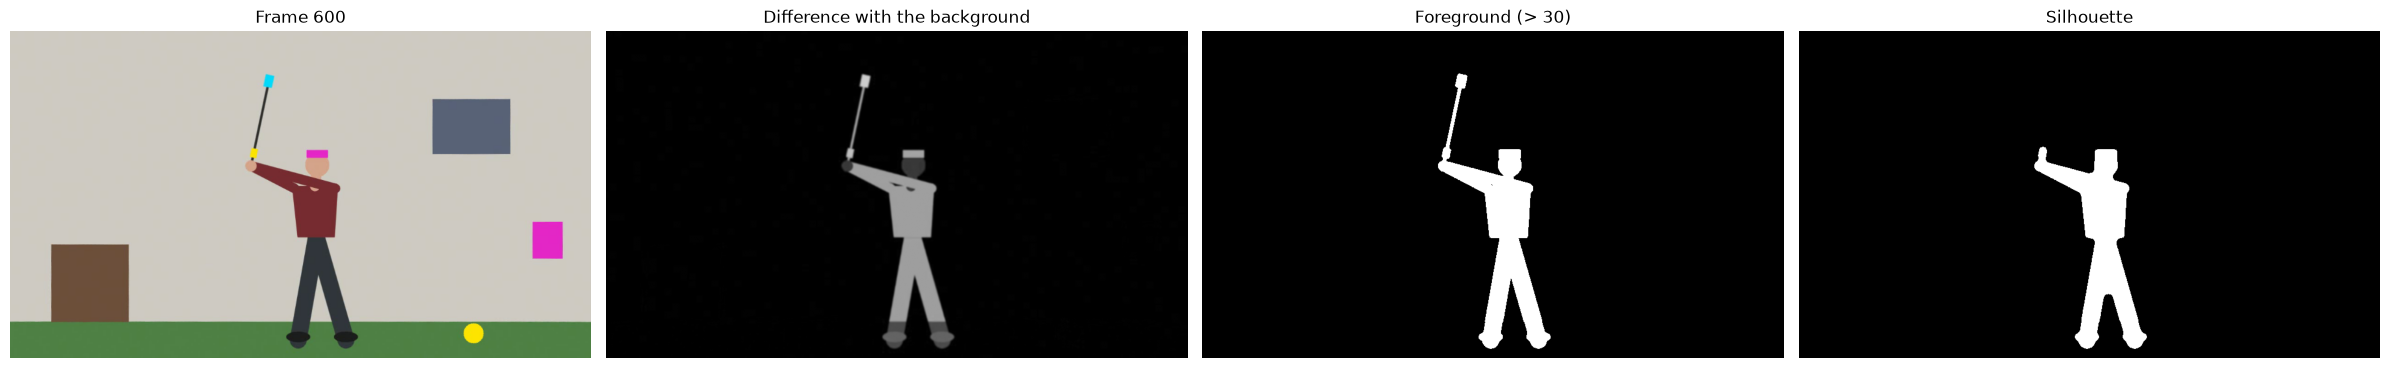

In [3]:
frame_id = 600   # a frame of the backswing
frame = get_frames(videopath, [frame_id])[0]

# Same steps as segment_player(), one by one
blurred = cv2.GaussianBlur(frame, (5, 5), 0)
b, g, r = cv2.split(cv2.absdiff(blurred, background))
diff = cv2.max(cv2.max(b, g), r)
foreground, silhouette = segment_player(frame, background)

centre, tilt = get_silhouette_pose(silhouette)
print(f"Silhouette: centre = ({centre[0]:.1f}, {centre[1]:.1f}) px, tilt = {tilt:.1f} degrees")

cv2.imwrite(os.path.join(results_path, "C2_segmentacion.png"), np.hstack([diff, foreground, silhouette]))
show_images([frame, diff, foreground, silhouette], [f"Frame {frame_id}", "Difference with the background", f"Foreground (> {config.DIFF_THRESHOLD})", "Silhouette"], size=6)

### **Tarea C.3:** Marcadores por color

Cada marcador se segmenta en HSV con ``cv2.inRange()``, como en la Práctica 1, pero **solo dentro del primer plano**: en la escena hay un póster magenta y un cubo amarillo del mismo color que dos marcadores, y no molestan porque no se mueven. El centro del marcador se calcula con los momentos del contorno.

cap  : centre = (506.6, 202.5), bounding box = (489, 196, 36, 14)
grip : centre = (402.3, 201.2), bounding box = (396, 193, 14, 17)
club : centre = (427.0, 82.2), bounding box = (418, 72, 18, 22)


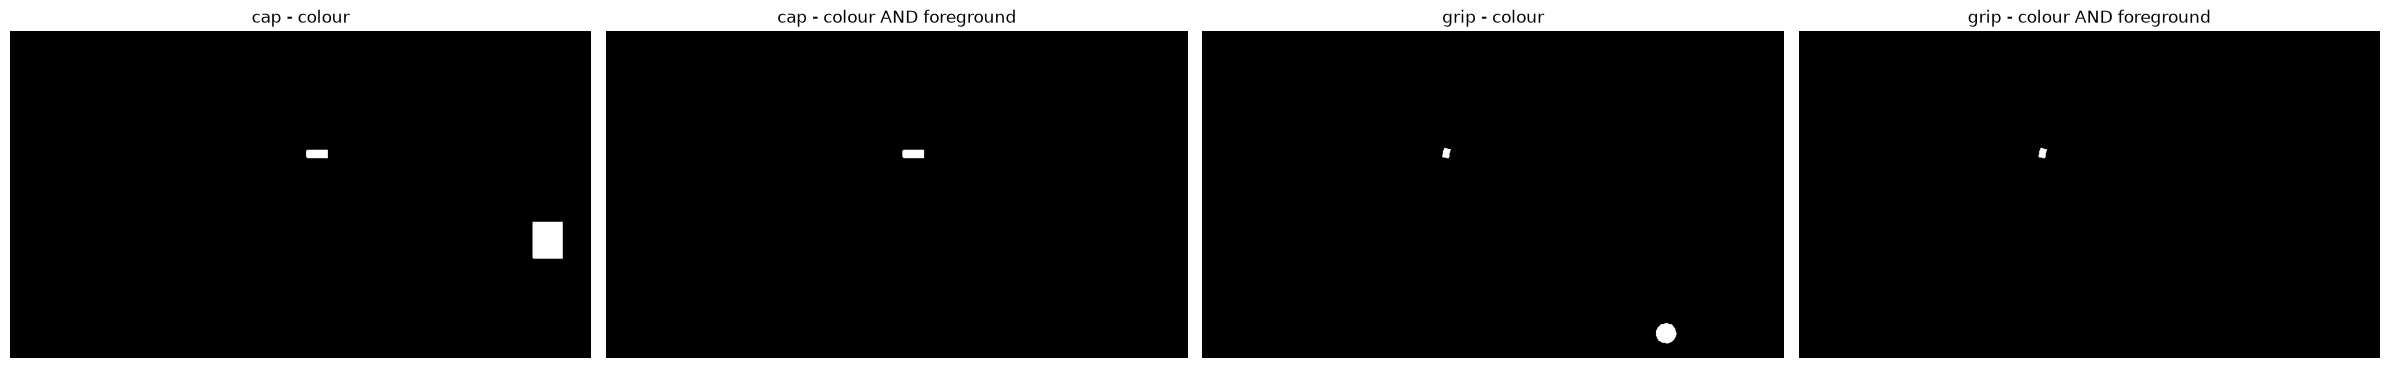

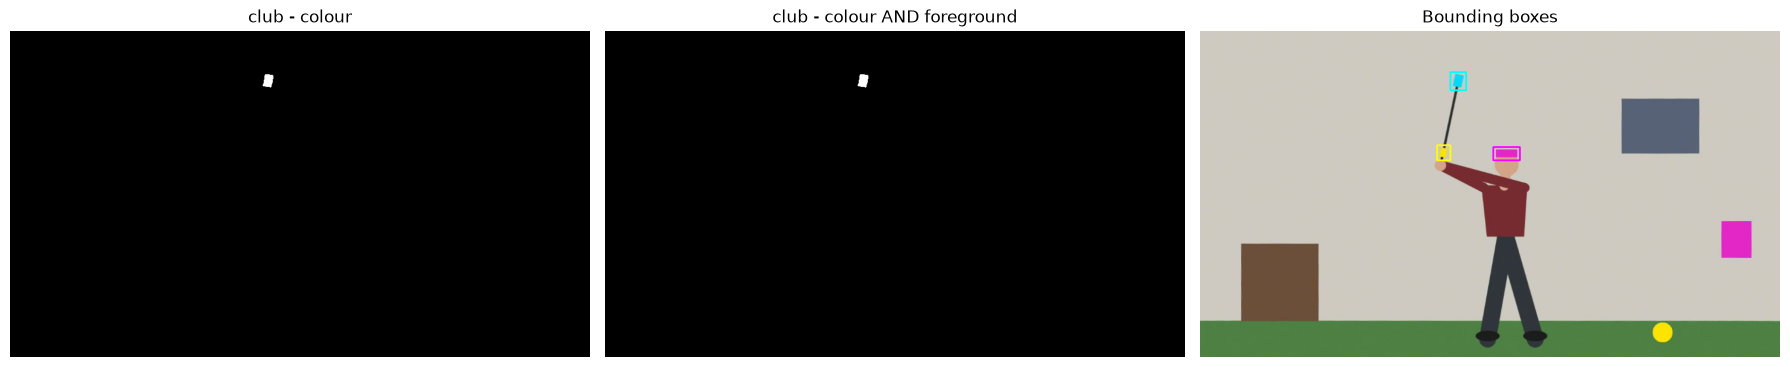

In [4]:
search = cv2.dilate(foreground, np.ones((5, 5), np.uint8))
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

markers_image = frame.copy()
masks, positions = [], {}
for name in config.MARKERS:
    lower, upper = config.MARKERS[name]
    color_mask = cv2.inRange(hsv, lower, upper)
    masks.append(color_mask)                               # colour only
    masks.append(cv2.bitwise_and(color_mask, search))      # colour inside the foreground
    marker = MarkerTracker(name)
    positions[name] = marker.update(hsv, search)
    x, y, w, h = marker.box
    cv2.rectangle(markers_image, (x - 4, y - 4), (x + w + 4, y + h + 4), config.MARKER_COLORS[name], 2)
    print(f"{name:5s}: centre = ({positions[name][0]:.1f}, {positions[name][1]:.1f}), bounding box = {marker.box}")

cv2.imwrite(os.path.join(results_path, "C3_mascaras.png"), np.hstack(masks))
write_image(results_path, "C3_marcadores.png", markers_image)
titles = [f"{name} - {kind}" for name in config.MARKERS for kind in ["colour", "colour AND foreground"]]
show_images(masks[:4], titles[:4], size=6)
show_images(masks[4:] + [markers_image], titles[4:] + ["Bounding boxes"], size=6)

### **Tarea C.4:** Ángulo del palo con Canny + Hough

Entre los dos marcadores del palo se aplica ``cv2.Canny()`` y ``cv2.HoughLinesP()``, como en la Práctica 4. De los segmentos que devuelve Hough (también salen los brazos o las piernas) se elige el más largo que coincide con la dirección de los marcadores. Los marcadores dan el sentido (de las manos a la cabeza del palo) y Hough mide el ángulo sobre toda la varilla.

Angle from the markers: 78.3 degrees - angle from Hough: 78.1 degrees


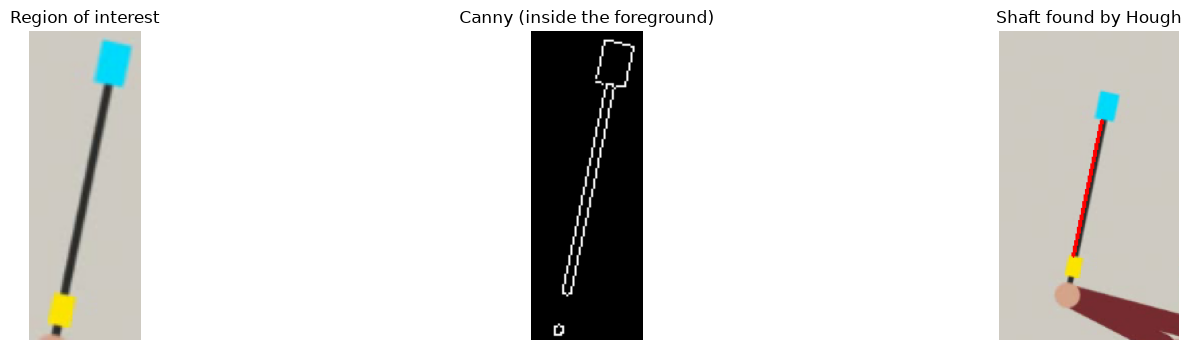

In [5]:
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
grip, club = positions["grip"], positions["club"]

# Edges in the region of interest (same steps as find_club_line())
x0, x1 = int(min(grip[0], club[0]) - 15), int(max(grip[0], club[0]) + 15)
y0, y1 = int(min(grip[1], club[1]) - 15), int(max(grip[1], club[1]) + 15)
edges = cv2.bitwise_and(cv2.Canny(gray[y0:y1, x0:x1], config.CANNY_LOW, config.CANNY_HIGH), search[y0:y1, x0:x1])

angle, segment = find_club_line(gray, search, grip, club)
marker_angle = np.degrees(np.arctan2(grip[1] - club[1], club[0] - grip[0]))
print(f"Angle from the markers: {marker_angle:.1f} degrees - angle from Hough: {angle:.1f} degrees")

line_image = frame.copy()
xa, ya, xb, yb = [int(v) for v in segment]
cv2.line(line_image, (xa, ya), (xb, yb), (0, 0, 255), 2)
cv2.imwrite(os.path.join(results_path, "C4_canny.png"), edges)
write_image(results_path, "C4_hough.png", line_image)
show_images([frame[y0:y1, x0:x1], edges, line_image[max(y0 - 40, 0):y1 + 40, max(x0 - 40, 0):x1 + 40]], ["Region of interest", "Canny (inside the foreground)", "Shaft found by Hough"], size=6)

### **Tarea C.5:** Tracker sobre todo el vídeo

``analyse_video()`` repite los pasos anteriores en cada frame con un ``SwingTracker``. Cada marcador lleva un filtro de Kalman de velocidad constante (el de la Práctica 5): la predicción dice dónde buscar el marcador en el frame siguiente y lo sustituye cuando no se ve. El vídeo con la silueta, las *bounding boxes*, las trayectorias y los FPS se guarda en ``results``.

754 frames tracked at 240 fps - scale: 5.27 mm/px
cap   seen in 87 % of the frames
grip  seen in 87 % of the frames
club  seen in 87 % of the frames


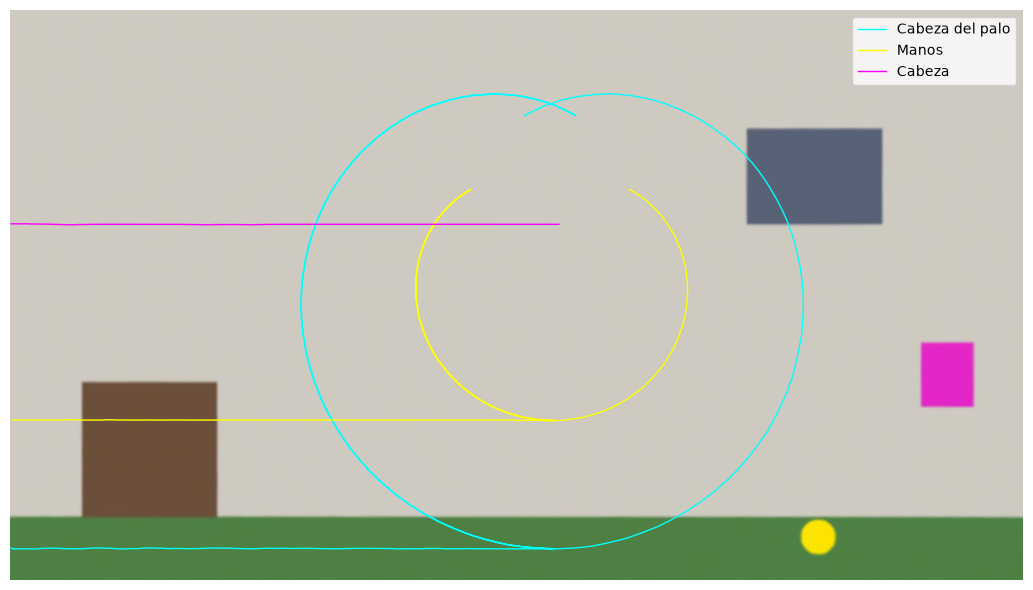

In [6]:
swing = analyse_video(videopath, calib, save_path=os.path.join(results_path, "C5_tracking.avi"))
print(f"{len(swing['t'])} frames tracked at {swing['fps']:.0f} fps - scale: {swing['mm_per_px']:.2f} mm/px")
for k, name in enumerate(config.MARKERS):
    print(f"{name:5s} seen in {100 * swing['detected'][:, k].mean():.0f} % of the frames")

# Trajectories of the hands and the club head over the background
trajectories = cv2.cvtColor(background, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(11, 6))
plt.imshow(trajectories)
plt.plot(swing["club"][:, 0], swing["club"][:, 1], color="cyan", linewidth=1, label="Cabeza del palo")
plt.plot(swing["grip"][:, 0], swing["grip"][:, 1], color="yellow", linewidth=1, label="Manos")
plt.plot(swing["cap"][:, 0], swing["cap"][:, 1], color="magenta", linewidth=1, label="Cabeza")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_path, "C5_trayectorias.png"), dpi=150)
plt.show()

### **Tarea C.6:** Detección de las posiciones P

A partir de aquí ya no se trabaja con imágenes, sino con las trayectorias:

| Posición | Criterio |
|---|---|
| P4 (cima) | Punto más alto de las manos antes del momento más rápido del swing |
| P1 (address) | Retrocediendo desde P4 por la subida, el último frame con las manos quietas |
| P7 (impacto) | Después de P4, el frame en el que las manos vuelven a donde estaban en P1 |
| P2 (palo horizontal, subida) | Primer frame entre P1 y P4 en que la cabeza del palo sube por encima de las manos |
| P6 (palo horizontal, bajada) | Último frame entre P4 y P7 en que la cabeza del palo baja por debajo de las manos |

Index in the swing arrays: {'P1': 371, 'P2': 435, 'P4': 522, 'P6': 573, 'P7': 593}
Frame of the video:        {'P1': 491, 'P2': 555, 'P4': 642, 'P6': 693, 'P7': 713}


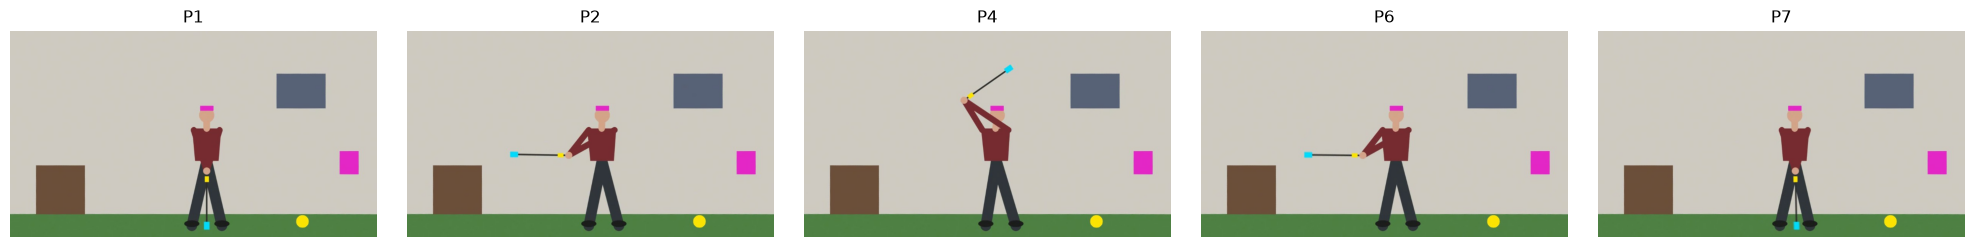

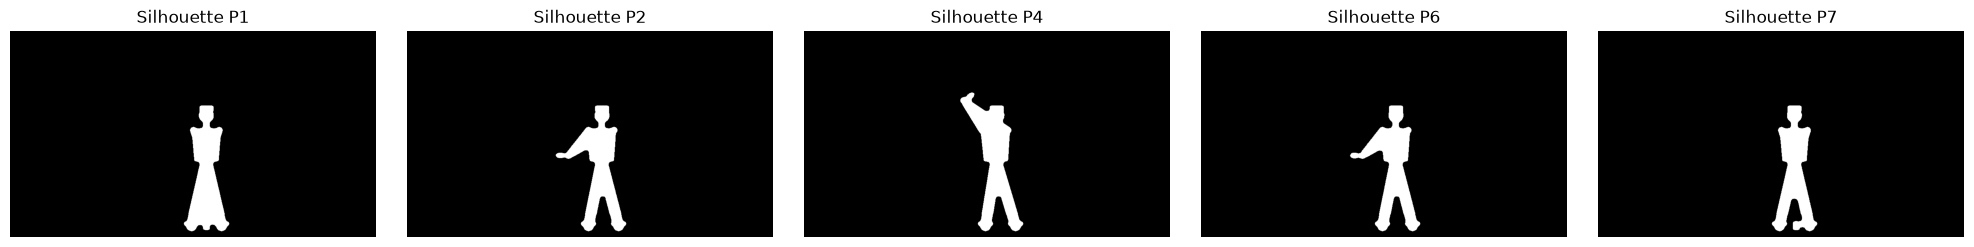

True

In [7]:
positions = detect_positions(swing)
first_frame = int(round(swing["t"][0] * swing["fps"]))
print("Index in the swing arrays:", positions)
print("Frame of the video:       ", {name: i + first_frame for name, i in positions.items()})

images = get_position_images(swing, positions)
show_images([images[name][0] for name in config.POSITIONS], config.POSITIONS, size=4)
show_images([images[name][2] for name in config.POSITIONS], [f"Silhouette {name}" for name in config.POSITIONS], size=4)
cv2.imwrite(os.path.join(results_path, "C6_posiciones.png"), np.hstack([images[name][0] for name in config.POSITIONS]))

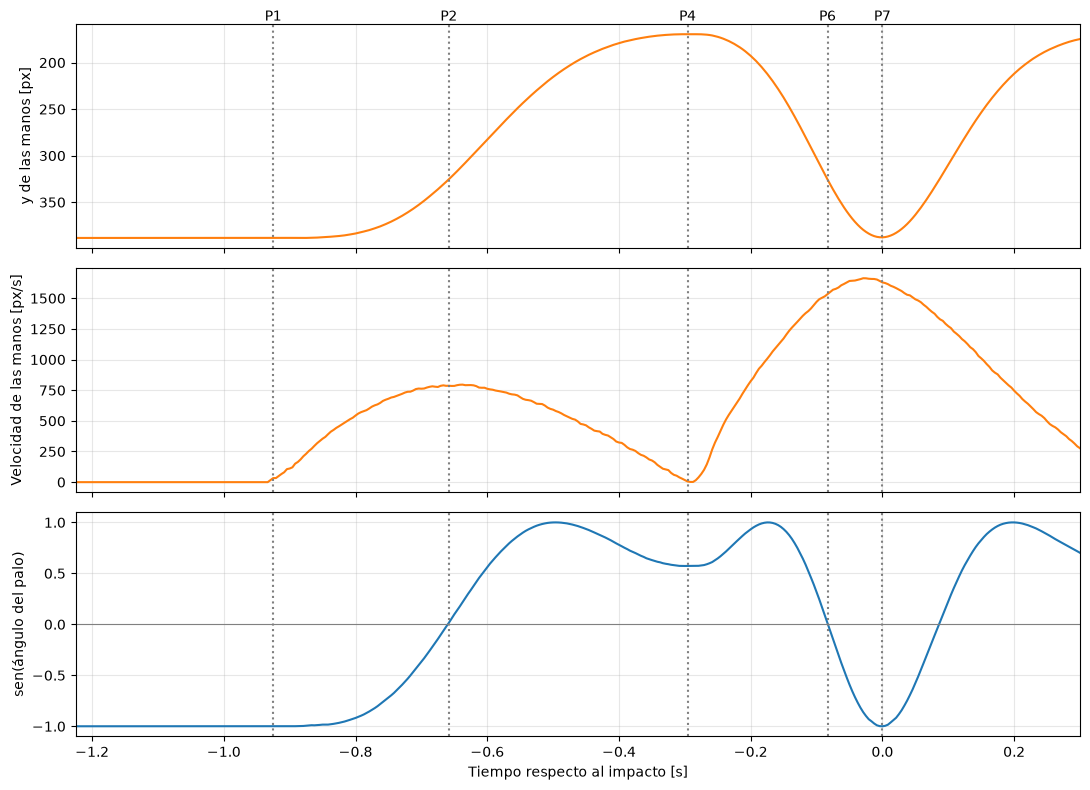

In [8]:
# Signals used to find the positions
t = swing["t"] - swing["t"][positions["P7"]]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(t, swing["hands"][:, 1], color="tab:orange")
axes[0].invert_yaxis()
axes[0].set_ylabel("y de las manos [px]")
axes[1].plot(t, swing["hands_speed"], color="tab:orange")
axes[1].set_ylabel("Velocidad de las manos [px/s]")
axes[2].plot(t, np.sin(swing["rotation"]), color="tab:blue")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set_ylabel("sen(ángulo del palo)")
axes[2].set_xlabel("Tiempo respecto al impacto [s]")
for ax in axes:
    for name, i in positions.items():
        ax.axvline(t[i], color="gray", linestyle=":")
    ax.grid(alpha=0.3)
for name, i in positions.items():
    axes[0].text(t[i], axes[0].get_ylim()[1], name, ha="center", va="bottom")
axes[0].set_xlim(t[positions["P1"]] - 0.3, t[positions["P7"]] + 0.3)
plt.tight_layout()
plt.savefig(os.path.join(results_path, "C6_senales.png"), dpi=150)
plt.show()

### **Tarea C.7:** Medidas del swing

Las posiciones se miden respecto a la cabeza del palo en el *address* y se dividen por la altura del jugador (distancia vertical entre la cabeza del palo y la gorra en P1). Así se pueden comparar jugadores de distinto tamaño o a distinta distancia de la cámara.

In [9]:
measures = compute_measures(swing, positions)
print(f"Height of the player: {swing['height']:.0f} px = {swing['height'] * swing['mm_per_px'] / 10:.0f} cm (club head - cap at address)\n")

print("measure        " + "".join(f"{name:>9s}" for name in config.POSITIONS))
for measure in ["hands_x", "hands_y", "head_x", "head_y", "club", "sway", "tilt"]:
    print(f"{measure:15s}" + "".join(f"{measures[f'{name}.{measure}']:9.3f}" for name in config.POSITIONS))
print()
for measure in config.GLOBAL_MEASURES:
    print(f"{measure:12s} = {measures[measure]:.2f} {MEASURE_INFO[measure][2]}")

Height of the player: 307 px = 162 cm (club head - cap at address)

measure               P1       P2       P4       P6       P7
hands_x            0.000   -0.368   -0.256   -0.365    0.005
hands_y            0.395    0.600    1.107    0.600    0.398
head_x             0.000   -0.013   -0.032   -0.012   -0.001
head_y             0.000    0.000    0.000    0.000    0.000
club               0.000   90.821  235.047   90.608    1.006
sway               0.000   -0.036   -0.055   -0.036    0.000
tilt              -0.075   -4.677   -8.969   -4.662   -0.157

tempo        = 2.13 
hands_speed  = 8.77 m/s
club_speed   = 20.90 m/s
club_peak    = -12.50 ms


### **Tarea C.8:** Referencia

La referencia se construye con varios swings de un buen jugador, grabados con el mismo montaje. De cada medida se guardan la **media** y la **desviación típica**: la desviación dice cuánto varía la propia referencia y de ella sale la tolerancia. También se guardan las siluetas de sus posiciones P para dibujar el fantasma. Este paso es *offline*, como la calibración (``register_reference.py`` hace lo mismo).

In [10]:
reference_paths = sorted(glob.glob(os.path.join(config.DATA_PATH, "videos", "reference", "*.mp4")))
swings_measures = register_reference(reference_paths, calib)
reference = load_reference()

print("\nmeasure           mean      std")
for key in ["P4.hands_y", "P4.sway", "P4.club", "P7.hands_x", "tempo", "club_speed", "club_peak"]:
    mean, std = reference["measures"][key]
    print(f"{key:14s} {mean:8.3f} {std:8.3f}")

reference_01.mp4: P frames {'P1': 374, 'P2': 446, 'P4': 553, 'P6': 609, 'P7': 620}


reference_02.mp4: P frames {'P1': 374, 'P2': 444, 'P4': 550, 'P6': 607, 'P7': 617}


reference_03.mp4: P frames {'P1': 376, 'P2': 444, 'P4': 551, 'P6': 608, 'P7': 618}


reference_04.mp4: P frames {'P1': 375, 'P2': 445, 'P4': 551, 'P6': 608, 'P7': 618}


reference_05.mp4: P frames {'P1': 375, 'P2': 446, 'P4': 554, 'P6': 611, 'P7': 622}
Reference saved in ../results/reference (5 swings)

measure           mean      std
P4.hands_y        1.163    0.006
P4.sway          -0.023    0.002
P4.club         250.331    2.953
P7.hands_x       -0.002    0.012
tempo             2.634    0.022
club_speed       39.333    0.436
club_peak         0.833    1.863


### **Tarea C.9:** Comparación con la referencia

Para cada medida, con $d = |x - \mu|$:

- $d \le T_1$ → **bien** (verde), con $T_1 = \max(K_{verde} \cdot \sigma,\ tol_{min})$
- $T_1 < d \le T_2$ → **a mejorar** (naranja), con $T_2 = T_1 \cdot K_{rojo} / K_{verde}$
- $d > T_2$ → **mal** (rojo)

``K_VERDE`` y ``K_ROJO`` están en ``config.py``. El valor $z = d / T_1$ no tiene unidades, así que sirve para ordenar los fallos de medidas distintas. El resumen da una nota, las tres prioridades y la primera posición en la que aparece un fallo.

In [11]:
cm_per_unit = swing["height"] * swing["mm_per_px"] / 10
rows = compare(measures, reference, cm_per_unit)
summary = summarise(rows)
print_report(rows, summary)

Nota: 7.7 / 10   (23 bien, 5 a mejorar, 5 mal)
P1 address
   manos (horizontal): bien
   manos (altura): bien
   inclinación del cuerpo: bien
P2 palo horizontal (subida)
   manos (horizontal): bien
   manos (altura): bien
   cabeza (horizontal): bien
   cabeza (altura): bien
   desplazamiento lateral: bien
   inclinación del cuerpo: bien
P4 cima
   manos (horizontal): mal (22.6 cm más a la izquierda)
   manos (altura): a mejorar (9.1 cm más bajas)
   cabeza (horizontal): bien
   cabeza (altura): bien
   giro del palo: mal (15.3 grados menos giro)
   desplazamiento lateral: a mejorar (5.1 cm más a la izquierda)
   inclinación del cuerpo: bien
P6 palo horizontal (bajada)
   manos (horizontal): mal (10.5 cm más a la izquierda)
   manos (altura): a mejorar (7.0 cm más altas)
   cabeza (horizontal): bien
   cabeza (altura): bien
   desplazamiento lateral: bien
   inclinación del cuerpo: bien
P7 impacto
   manos (horizontal): bien
   manos (altura): bien
   cabeza (horizontal): bien
   cabez

### **Tarea C.10:** Salida

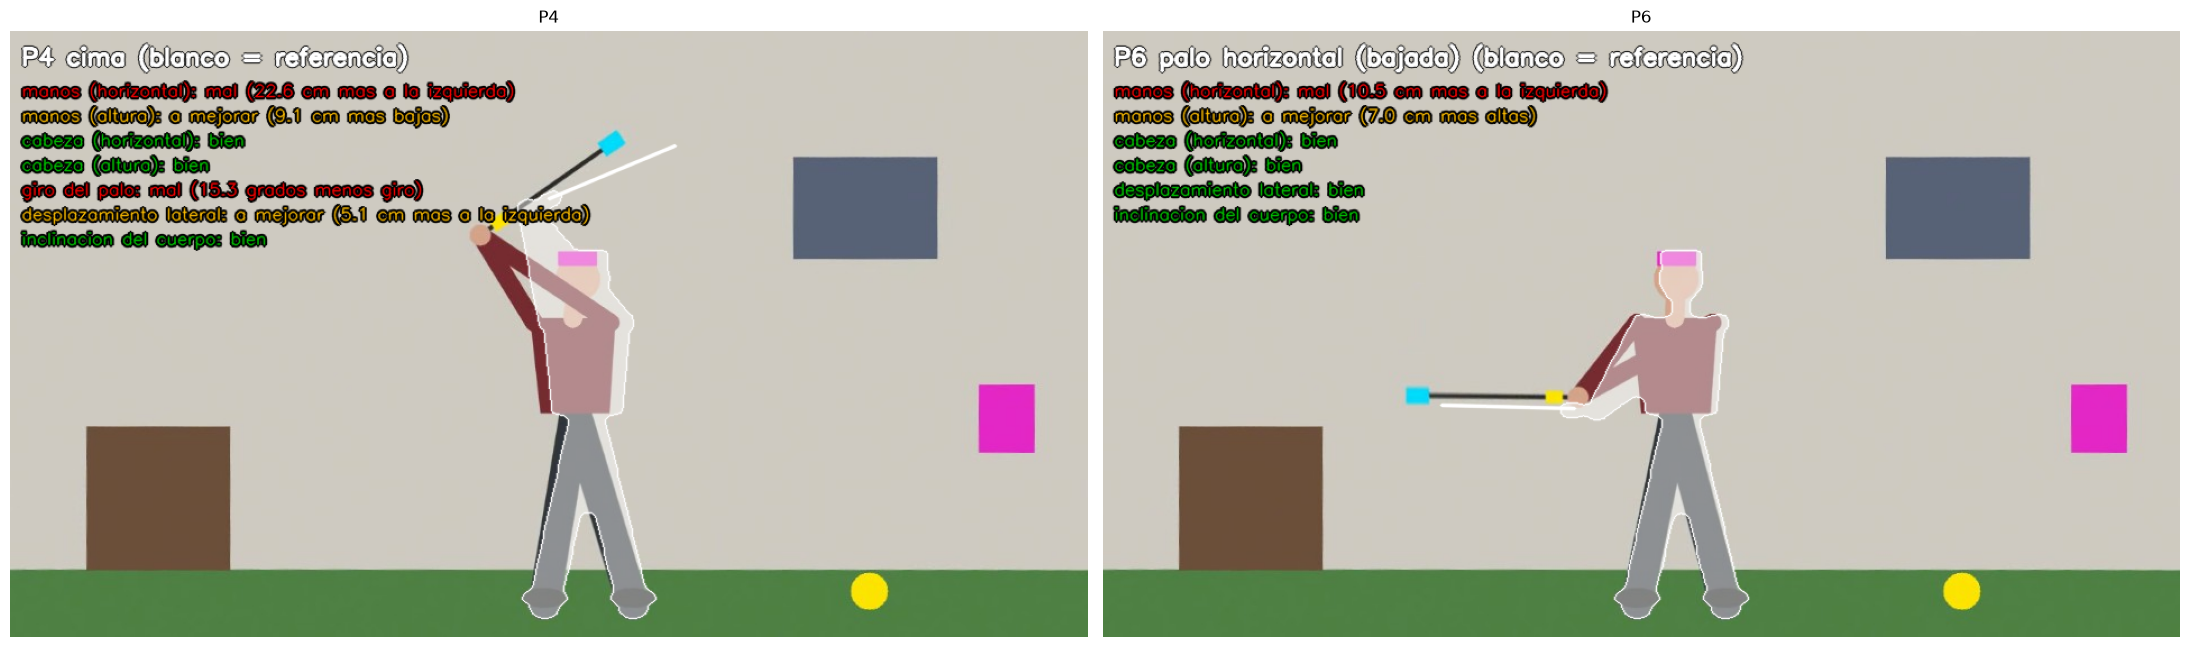

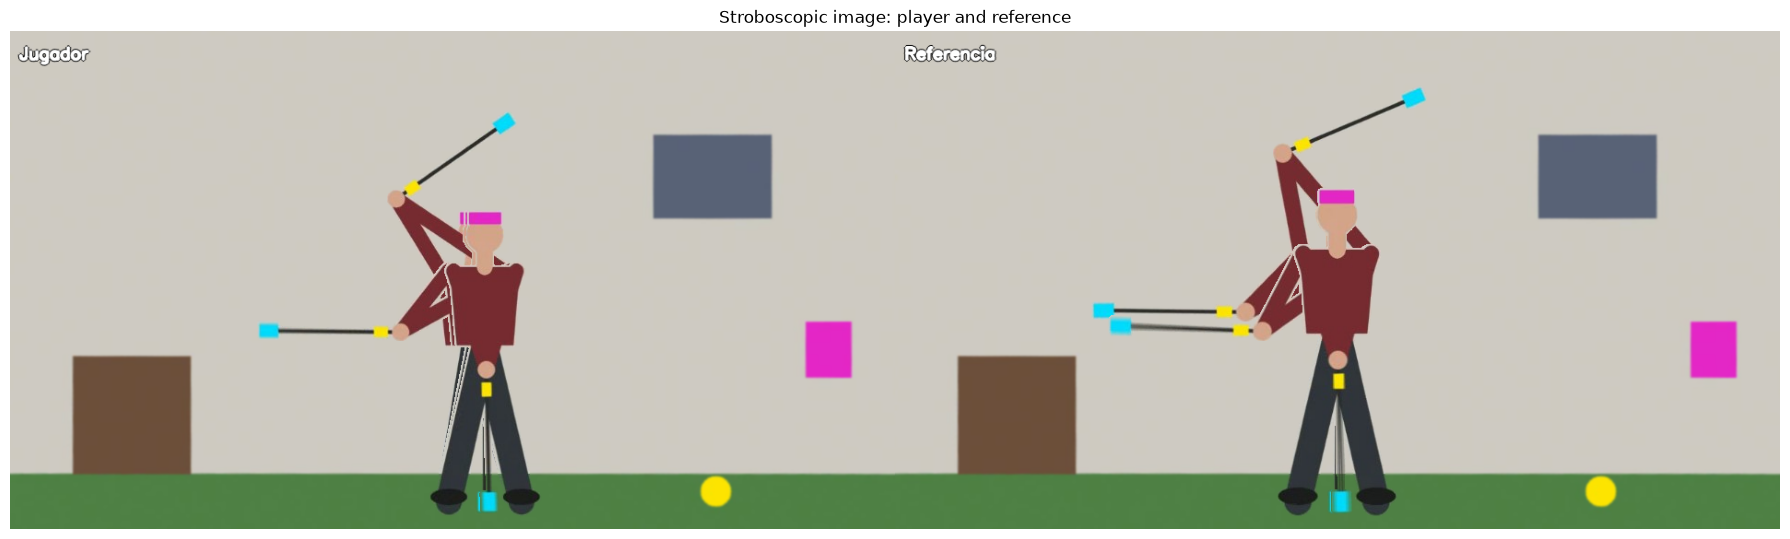

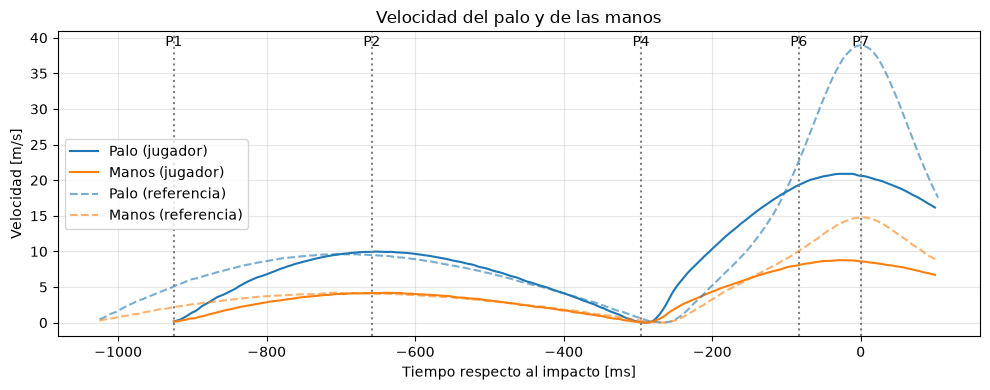

In [12]:
outputs = save_results(os.path.join(results_path, "C10_salida"), swing, positions, reference, rows, summary)

# Ghost: silhouette and club of the reference (white) over the player in every position
show_images([outputs["P4"], outputs["P6"]], ["P4", "P6"], size=11)
show_images([outputs["strobe"]], ["Stroboscopic image: player and reference"], size=18)
plot_speed(swing, positions, reference)

#### **EXTRA C.9:** efecto de ``K_VERDE`` y ``K_ROJO``

Repetimos la comparación con distintos valores de las dos constantes y contamos cuántas medidas caen en cada nivel.

In [13]:
# EXTRA: number of measures in every level for several tolerances
print("K_VERDE  K_ROJO   bien  a mejorar  mal   score")
for k_verde, k_rojo in [(1.0, 2.0), (2.0, 4.0), (3.0, 6.0), (2.0, 8.0)]:
    config.K_VERDE, config.K_ROJO = k_verde, k_rojo
    levels = []
    for row in rows:
        key = f"{row['position']}.{row['name']}" if row["position"] else row["name"]
        mean, std = reference["measures"][key]
        levels.append(evaluate(row["value"], mean, std, MEASURE_INFO[row["name"]][1], k_verde, k_rojo)[0])
    score = 10 * (levels.count("bien") + 0.5 * levels.count("a mejorar")) / len(levels)
    print(f"{k_verde:7.1f} {k_rojo:7.1f} {levels.count('bien'):6d} {levels.count('a mejorar'):10d} {levels.count('mal'):4d} {score:7.1f}")
config.K_VERDE, config.K_ROJO = 2.0, 4.0

K_VERDE  K_ROJO   bien  a mejorar  mal   score
    1.0     2.0     23          5    5     7.7
    2.0     4.0     23          5    5     7.7
    3.0     6.0     23          6    4     7.9
    2.0     8.0     23          7    3     8.0


#### **EXTRA C.4:** Hough frente a los marcadores

En todos los frames del swing comparamos el ángulo del palo que da Hough con el que dan los dos marcadores, y contamos en cuántos frames Hough encuentra la varilla.

Frames between P1 and P7 in which Hough finds the shaft: 97 %
Difference Hough - markers: mean 0.48 degrees, max 8.61 degrees


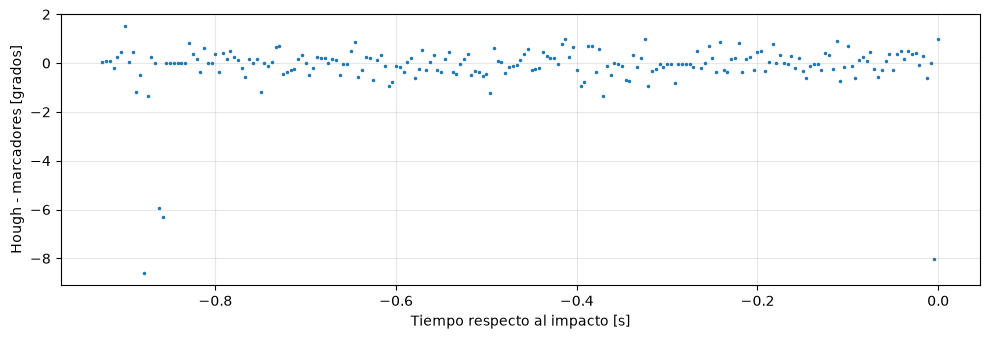

In [14]:
# EXTRA: angle of the shaft from Hough against the angle from the markers, frame by frame
marker_angles = np.degrees(np.arctan2(swing["grip"][:, 1] - swing["club"][:, 1], swing["club"][:, 0] - swing["grip"][:, 0]))
difference = (swing["angle"] - marker_angles + 180) % 360 - 180
inside = slice(positions["P1"], positions["P7"] + 1)
found = np.abs(difference[inside]) > 1e-9   # when Hough fails, the stored angle is the one of the markers
print(f"Frames between P1 and P7 in which Hough finds the shaft: {100 * found.mean():.0f} %")
print(f"Difference Hough - markers: mean {np.mean(np.abs(difference[inside][found])):.2f} degrees, max {np.max(np.abs(difference[inside][found])):.2f} degrees")

plt.figure(figsize=(10, 3.5))
plt.plot(t[inside], difference[inside], ".", markersize=3)
plt.xlabel("Tiempo respecto al impacto [s]")
plt.ylabel("Hough - marcadores [grados]")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(results_path, "extra_hough_vs_marcadores.png"), dpi=150)
plt.show()